Astroids

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [63]:
astroids = pd.read_csv("data/near_earth_asteroids_2025.csv")

C:\Users\malin\AppData\Local\Temp\ipykernel_3224\1600071155.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  astroids = pd.read_csv("data/near_earth_asteroids_2025.csv")


In [64]:
display(astroids)

,spkid,full_name,pdes,name,pha,H,diameter_km,diameter_m,diameter_is_estimated,size_category,...,per_y,moid_au,moid_km,moid_lunar_distances,n,condition_code,first_obs,last_obs,data_arc,data_arc_years
0,20000433,433 Eros (A898 PA),433,Eros,False,10.39,16.840000,16840.0,False,Large (>1 km) — City killer+,...,1.76,0.148000,22140485.0,57.60,0.5598,0.0,1893-10-29,2021-05-13,46582.0,127.53
1,20000719,719 Albert (A911 TB),719,Albert,False,15.59,2.706830,2706.8,True,Large (>1 km) — City killer+,...,4.28,0.201000,30069172.0,78.22,0.2302,0.0,1911-10-04,2026-03-20,41806.0,114.46
2,20000887,887 Alinda (A918 AA),887,Alinda,False,13.82,4.200000,4200.0,False,Large (>1 km) — City killer+,...,3.89,0.079700,11922950.0,31.02,0.2533,0.0,1918-02-09,2025-08-27,39281.0,107.55
3,20001036,1036 Ganymed (A924 UB),1036,Ganymed,False,9.17,37.675000,37675.0,False,Large (>1 km) — City killer+,...,4.35,0.343000,51312070.0,133.49,0.2266,0.0,1924-10-23,2026-03-22,37040.0,101.41
4,20001221,1221 Amor (1932 EA1),1221,Amor,False,17.37,1.000000,1000.0,False,Large (>1 km) — City killer+,...,2.66,0.108000,16156570.0,42.03,0.3705,0.0,1932-03-12,2025-02-19,33947.0,92.94
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41276,54606826,(2026 FJ4),2026 FJ4,NaN,False,20.85,0.240138,240.1,True,Medium (140m-1km) — Regional damage,...,3.53,0.191000,28573193.0,74.33,0.2795,9.0,2026-03-22,2026-03-24,2.0,0.01
41277,54606825,(2026 FK4),2026 FK4,NaN,False,27.55,0.010976,11.0,True,Tiny (<25m) — Airburst/harmless,...,3.08,0.000852,127457.0,0.33,0.3199,9.0,2026-03-21,2026-03-24,3.0,0.01
41278,54606827,(2026 FL4),2026 FL4,NaN,False,27.07,0.013692,13.7,True,Tiny (<25m) — Airburst/harmless,...,4.40,0.008870,1326933.0,3.45,0.2238,9.0,2026-03-21,2026-03-23,2.0,0.01
41279,54606828,(2026 FM4),2026 FM4,NaN,False,25.77,0.024915,24.9,True,Tiny (<25m) — Airburst/harmless,...,2.88,0.039400,5894156.0,15.33,0.3427,8.0,2026-03-23,2026-03-25,2.0,0.01


spkid: JPL Small-Body SPK-ID (unique identifier) (DROP) \
full_name: Full asteroid name/designation (DROP) \
pdes = "designation", Primary designation, first name given to astroid when discovered in relation to when, by who, etc. (e.g. "2024 AA") (DROP) \
name = nickname of astroid (DROP) 

pha = "is_pha", Potentially Hazardous Asteroid flag (cateogircal, TARGET)

H: "absolute_magnitude", is a number for the brightness (gives an approximation of the size of the astroid) (numerical, KEEP) \
diameter_km: diameter of astroids, same info as diameter_m (numerical, KEEP) \
diamterer_m: same as above (numerical, DROP) \
diameter_is_estimated = whether the given diameter_km is estimated value or not, true or false (categorical, KEEP?) \
size_category: Large, Medium, Small, Tiny (categorical, KEEP) \

albedo: surface reflexivity of astroid, from 0 to 1 (numerical, KEEP) \
rot_per: "rotation_period_h", Rotation period in hours (numerical, KEEP) \
class: "neo_class", Orbit class: Apollo, Aten, Amor, or Atira

e: "eccentricity", Orbital eccentricity (0=circular, 1=parabolic) (numerical, KEEP) \
a: UNSURE \
i: UNSURE "inclination_deg",Orbital inclination in degrees \
q: UNSURE \
ad: UNSURE \
per: UNSURE same as under? (numerical, DROP?) \
per_y: UNSURE "orbital_period_yr", Orbital period in years (numerical, KEEP?) \

moid_au: Minimum Orbit Intersection Distance in AU (numerical, KEEP) \
moid_km: same as above, MOID in kilometers (numerical, DROP) \
moid_lunar_distances: same as above, MOID in lunar distances (1 LD ≈ 384,400 km)  (numerical, DROP) \

n: UNSURE !! "n_observations", Number of astrometric observations !!

condition_code: "orbit_condition_code", Orbit quality (0=best, 9=worst) (categorical, KEEP) \
first_obs: "first_observed", Date of first observation (numerical, DROP?) \
last_obs: "last_observed",	Date of most recent observation (numerical, DROP?) \
data_arc: "data_arc_days", Observation arc length in days (numerical, KEEP?) (say most about the certainty about the info in other columns?) \
data_arc_years: same as above, but in years (numerical, DROP)

In [65]:
#Target check
target_column = "pha"
target = astroids[target_column]
target.value_counts()

print(target.tolist().count(False)/len(target))

0.9384947070080667


https://www.kaggle.com/datasets/darkmatternet/nasa-near-earth-asteroids-and-close-approaches/data?select=near_earth_asteroids_2025+%281%29.csv


In [66]:
#Categorical values check
astroids["class"].value_counts()
#astroids["diameter_is_estimated"].value_counts()
#astroids["size_category"].value_counts()
#astroids["condition_code"].value_counts()

class
APO    23484
AMO    14408
ATE     3351
IEO       38
Name: count, dtype: int64

In [67]:
#Numerical values check
astroids["e"].value_counts()
astroids["rot_per"].value_counts()
astroids["a"].value_counts()
astroids["i"].value_counts()
astroids["q"].value_counts()
astroids["ad"].value_counts()
astroids["per"].value_counts()
astroids["per_y"].value_counts()
astroids["n"].value_counts()

n
0.25170    26
0.27520    24
0.25240    23
0.32200    21
1.09900    21
           ..
1.56000     1
0.98040     1
0.78800     1
0.80770     1
0.01303     1
Name: count, Length: 8584, dtype: int64

In [68]:
#Drop target and other irrelevant columns from data
data = astroids.drop(columns = "pha") #target
data_clean = data.drop(columns = ["spkid", "full_name", "pdes", "name", "first_obs", "last_obs", "data_arc", "data_arc_years"]) #irrelevant
data_clean = data_clean.drop(columns = ["diameter_m", "per", "moid_km", "moid_lunar_distances"]) #doubles

#Change types of columns with wrong types
data_clean['condition_code'] = data_clean['condition_code'].astype(str)

data_clean.head()
data_clean.dtypes

H                        float64
diameter_km              float64
diameter_is_estimated       bool
size_category             object
albedo                   float64
rot_per                  float64
class                     object
e                        float64
a                        float64
i                        float64
q                        float64
ad                       float64
per_y                    float64
moid_au                  float64
n                        float64
condition_code            object
dtype: object

array([[<Axes: title={'center': 'H'}>,
        <Axes: title={'center': 'diameter_km'}>,
        <Axes: title={'center': 'albedo'}>],
       [<Axes: title={'center': 'rot_per'}>,
        <Axes: title={'center': 'e'}>, <Axes: title={'center': 'a'}>],
       [<Axes: title={'center': 'i'}>, <Axes: title={'center': 'q'}>,
        <Axes: title={'center': 'ad'}>],
       [<Axes: title={'center': 'per_y'}>,
        <Axes: title={'center': 'moid_au'}>,
        <Axes: title={'center': 'n'}>]], dtype=object)

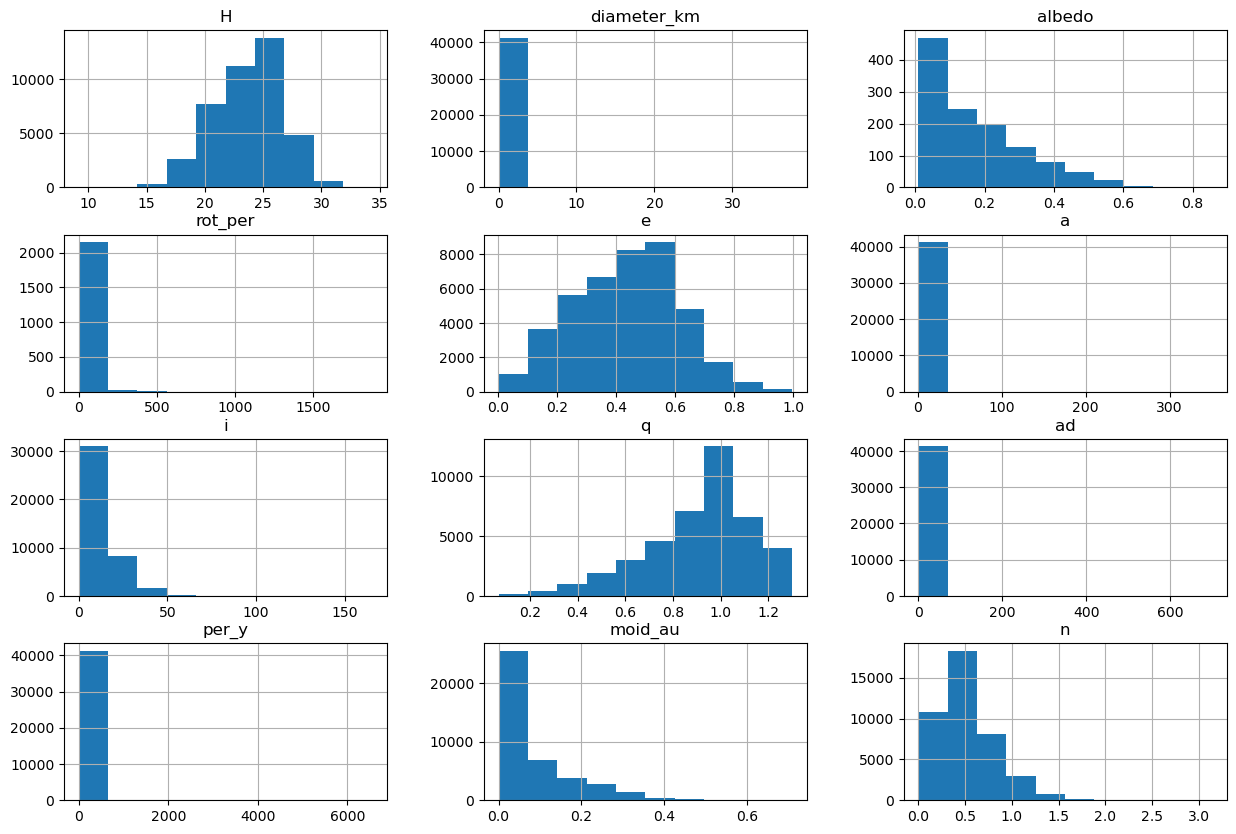

In [69]:
data_clean.hist(figsize=(15, 10))

Dummy

In [70]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

# Train/test split
data_train, data_test, target_train, target_test = train_test_split(data_clean, target, random_state=42,test_size=0.25)

Dummy = DummyClassifier(strategy="most_frequent")
Dummy.fit(data_train, target_train)

accuracy = Dummy.score(data_test, target_test)

print(f"Accuracy of DummyClassifier: {accuracy:.3f}")

Accuracy of DummyClassifier: 0.938


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector as selector
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

categorical_preprocessor = make_pipeline(SimpleImputer(missing_values=np.nan,strategy="most_frequent"),OneHotEncoder(handle_unknown="ignore"))
numerical_preprocessor = make_pipeline(SimpleImputer(missing_values=np.nan, strategy="mean"),StandardScaler())

numerical_columns_selector = selector(dtype_exclude=["object", "string", "category"])
categorical_columns_selector = selector(dtype_include=["object", "string", "category"])
numerical_columns = numerical_columns_selector(data_clean)
categorical_columns = categorical_columns_selector(data_clean)

from sklearn.compose import make_column_transformer
preprocessor = make_column_transformer((categorical_preprocessor, categorical_columns), (numerical_preprocessor, numerical_columns))

Logistic_reg.fit(data_train, target_train)
pred_original = Logistic_reg.predict(data_test)

Logistic_reg.fit(data_train, target_train)
#predicted_target = model.predict(data_test)

accuracy = Logistic_reg.score(data_test, target_test)
print(f"Accuracy of logistic regression: {accuracy:.3f}")

Logistic_reg_balanced = make_pipeline(
    preprocessor,
    LogisticRegression(
        max_iter=500,
        class_weight="balanced"
    )
)
Logistic_reg_balanced.fit(data_train, target_train)
#predicted_target = model.predict(data_test)

accuracy = Logistic_reg_balanced.score(data_test, target_test)
print(f"Accuracy of logistic regression: {accuracy:.3f}")

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

predicted_target = Logistic_reg_balanced.predict(data_test)

print("Accuracy:", accuracy_score(target_test, predicted_target))

print("Balanced accuracy:",
      balanced_accuracy_score(target_test, predicted_target))

print(classification_report(target_test, predicted_target))

Accuracy of logistic regression: 0.980
Accuracy: 0.9800406937312276
Balanced accuracy: 0.9871692109553278
              precision    recall  f1-score   support

       False       1.00      0.98      0.99      9682
        True       0.76      1.00      0.86       639

    accuracy                           0.98     10321
   macro avg       0.88      0.99      0.92     10321
weighted avg       0.98      0.98      0.98     10321



In [72]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    Logistic_reg,
    data_clean,
    target,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Cross-validation scores: [0.97965363 0.98049903 0.98328488 0.97880329 0.98401163]
Mean accuracy: 0.9812504928869373
Standard deviation: 0.002042844445660319


K-nearest neighbor

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_selector as selector

numerical_columns_selector = selector(dtype_exclude=["object", "string"])
numerical_columns = numerical_columns_selector(data_clean)
numerical_data = data_clean[numerical_columns]
                  
data_train, data_test, target_train, target_test = train_test_split(numerical_data, target, random_state=42, test_size=0.25)

from sklearn.neighbors import KNeighborsClassifier
Kneighbor = KNeighborsClassifier()
_ = Kneighbor.fit(data_train, target_train)

accuracy = Kneighbor.score(data_test, target_test)
model_name = Kneighbor.__class__.__name__
print(f"The test accuracy using a {model_name} is {accuracy:.3f}")

ValueError: Input X contains NaN.
KNeighborsClassifier does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values